# 加密货币价格可视化分析

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 注意顺序：先应用 seaborn 样式，再设置中文字体。
# sns.set_style 会覆盖 font.sans-serif 列表，若顺序颠倒中文会回退到 DejaVu Sans 而乱码。
sns.set_style('whitegrid')
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'Noto Sans CJK JP', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110

***

## BTC/ETH/SOL/BNB

### 数据加载

In [2]:
# 币种品牌色
COLORS = {'BTC': '#F7931A', 'ETH': '#627EEA', 'SOL': '#9945FF', 'BNB': '#999900'}
DATA_DIR = Path('../data')          # notebook 位于 notebook/，数据位于上级 data/
if not DATA_DIR.exists():
    DATA_DIR = Path('data')           # 兜底：若在项目根目录执行

FILES = {
    'BTC': 'btc_usdt_1h.csv',
    'ETH': 'eth_usdt_1h.csv',
    'SOL': 'sol_usdt_1h.csv',
    'BNB': 'bnb_usdt_1h.csv',
}

def load_hourly(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, parse_dates=['timestamp'])
    df = df.set_index('timestamp').sort_index()
    return df

data = {name: load_hourly(DATA_DIR / f) for name, f in FILES.items()}

for name, df in data.items():
    print(f'{name}: {df.shape[0]} 行, {df.index.min()} ~ {df.index.max()}, 列: {list(df.columns)}')

data['BTC'].head()

BTC: 49233 行, 2021-01-01 00:00:00 ~ 2026-08-14 08:00:00, 列: ['open', 'high', 'low', 'close', 'volume']
ETH: 49234 行, 2021-01-01 00:00:00 ~ 2026-08-14 09:00:00, 列: ['open', 'high', 'low', 'close', 'volume']
SOL: 49234 行, 2021-01-01 00:00:00 ~ 2026-08-14 09:00:00, 列: ['open', 'high', 'low', 'close', 'volume']
BNB: 49235 行, 2021-01-01 00:00:00 ~ 2026-08-14 10:00:00, 列: ['open', 'high', 'low', 'close', 'volume']


,open,high,low,close,volume
timestamp,,,,,
2021-01-01 00:00:00,28933.86,29034.02,28708.39,29012.30,13.669080
2021-01-01 01:00:00,28999.37,29475.57,28961.27,29405.80,24.403112
2021-01-01 02:00:00,29434.69,29465.08,29122.75,29187.35,16.717015
2021-01-01 03:00:00,29213.39,29356.23,29149.88,29282.51,8.101748
2021-01-01 04:00:00,29280.63,29405.54,29071.86,29215.39,6.428110


### 区间过滤：2021-01-01 ~ 2025-12-31

原始数据截至时间晚于 2025 年，统一截取分析区间。

In [3]:
START, END = '2021-01-01', '2025-12-31'

data = {name: df.loc[START:END] for name, df in data.items()}

for name, df in data.items():
    print(f'{name}: {df.index.min()} ~ {df.index.max()}，共 {len(df):,} 根小时K线')

# 对齐时间索引，便于后续合并比较
aligned = pd.concat({name: df['close'] for name, df in data.items()}, axis=1).dropna()
print('\n对齐后（四币种均有数据的时点数）:', aligned.shape)

BTC: 2021-01-01 00:00:00 ~ 2025-12-31 23:00:00，共 43,824 根小时K线
ETH: 2021-01-01 00:00:00 ~ 2025-12-31 23:00:00，共 43,824 根小时K线
SOL: 2021-01-01 00:00:00 ~ 2025-12-31 23:00:00，共 43,824 根小时K线
BNB: 2021-01-01 00:00:00 ~ 2025-12-31 23:00:00，共 43,824 根小时K线

对齐后（四币种均有数据的时点数）: (43824, 4)


### 收盘价折线图

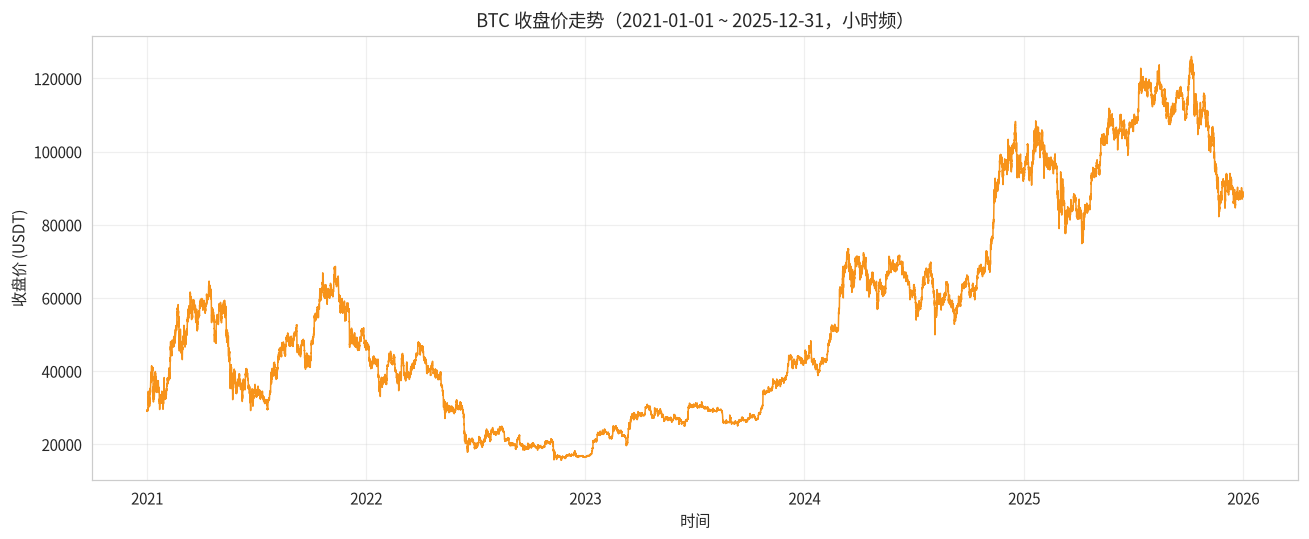

In [16]:
# BTC 收盘价
df = data['BTC']
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index, df['close'], color=COLORS['BTC'], linewidth=1.0)
ax.set_title('BTC 收盘价走势（2021-01-01 ~ 2025-12-31，小时频）')
ax.set_xlabel('时间'); ax.set_ylabel('收盘价 (USDT)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

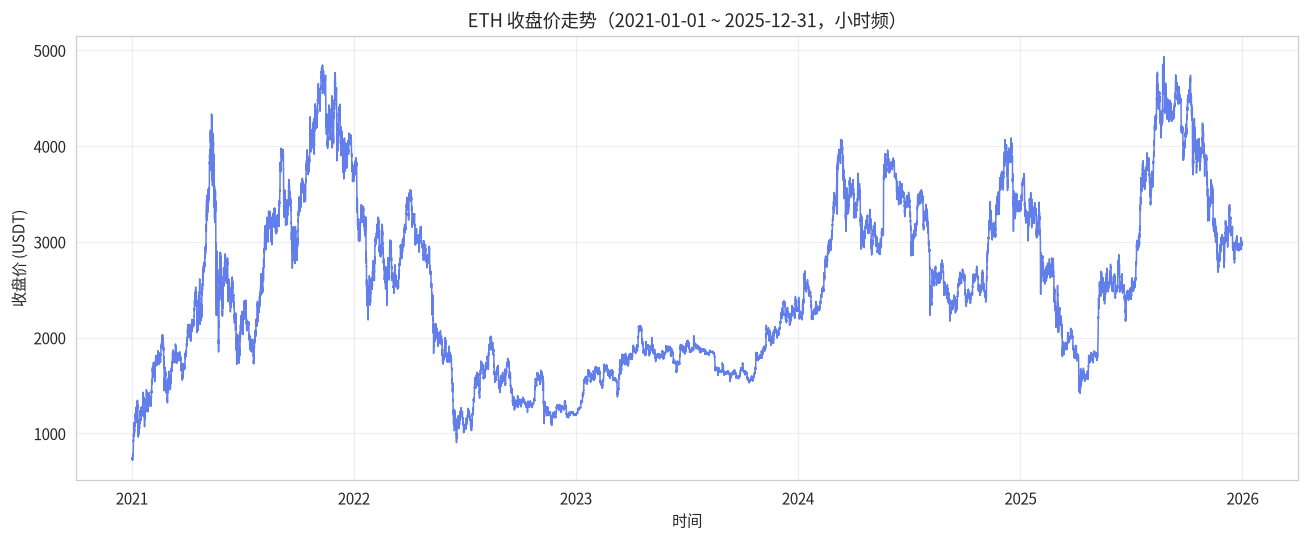

In [17]:
# ETH 收盘价
df = data['ETH']
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index, df['close'], color=COLORS['ETH'], linewidth=1.0)
ax.set_title('ETH 收盘价走势（2021-01-01 ~ 2025-12-31，小时频）')
ax.set_xlabel('时间'); ax.set_ylabel('收盘价 (USDT)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

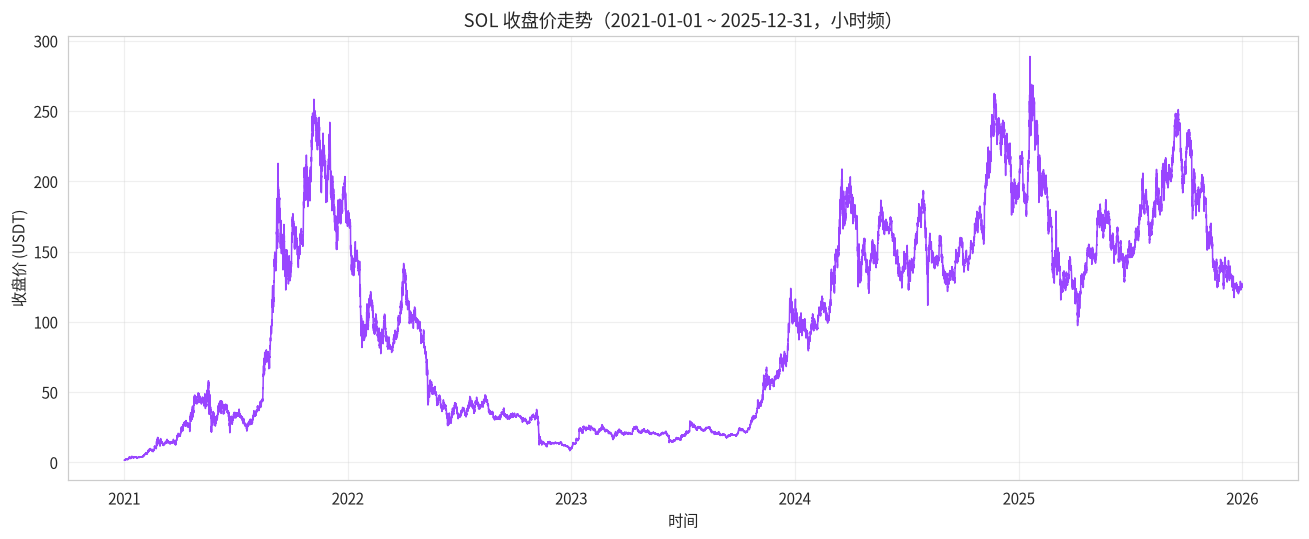

In [18]:
# SOL 收盘价
df = data['SOL']
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index, df['close'], color=COLORS['SOL'], linewidth=1.0)
ax.set_title('SOL 收盘价走势（2021-01-01 ~ 2025-12-31，小时频）')
ax.set_xlabel('时间'); ax.set_ylabel('收盘价 (USDT)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

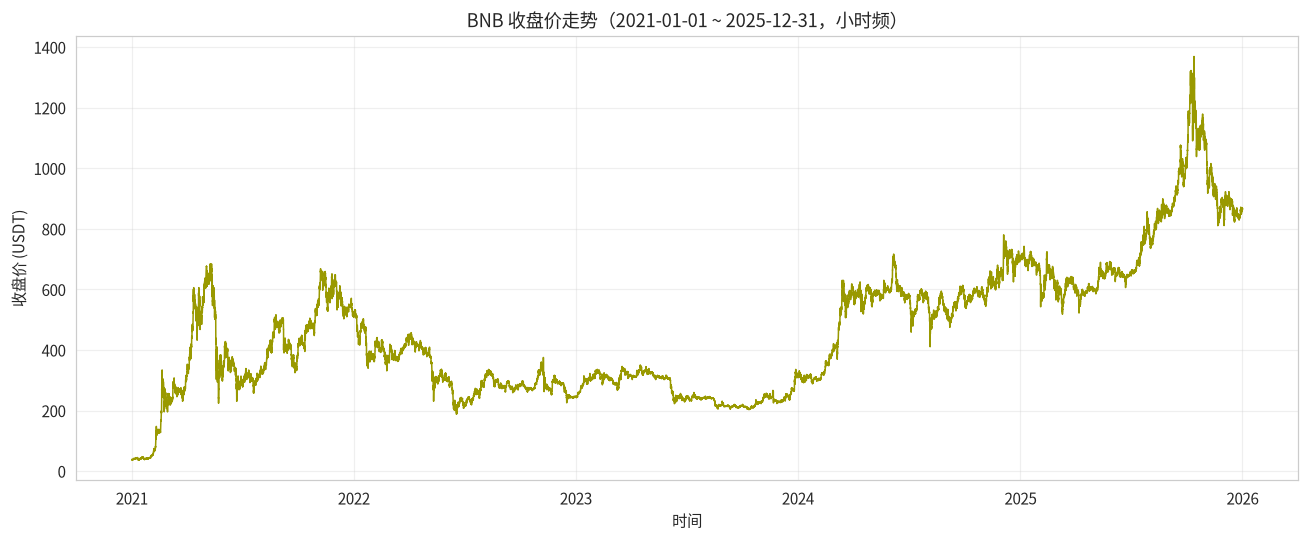

In [19]:
# BNB 收盘价
df = data['BNB']
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index, df['close'], color=COLORS['BNB'], linewidth=1.0)
ax.set_title('BNB 收盘价走势（2021-01-01 ~ 2025-12-31，小时频）')
ax.set_xlabel('时间'); ax.set_ylabel('收盘价 (USDT)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 归一化价格走势

本图时间窗口调整为 **2022-01-01 ~ 2025-12-31**：SOL 上市初期价格仅数美元，2021 年正处在与其他币种完全不同的早期发展阶段（低基数下涨幅会严重失真），2022 年起各币种才进入相对可比的状态。

采用**基期归一化**：以窗口内第一个收盘价（2022-01-01）为基准 100，`normalized = close / close_0 * 100`，在同一张图上对比四个币种的相对涨幅。

BTC: 归一化终值 = 187.9（基期 100，涨幅 +87.9%）
ETH: 归一化终值 = 79.9（基期 100，涨幅 -20.1%）
SOL: 归一化终值 = 72.4（基期 100，涨幅 -27.6%）
BNB: 归一化终值 = 167.0（基期 100，涨幅 +67.0%）


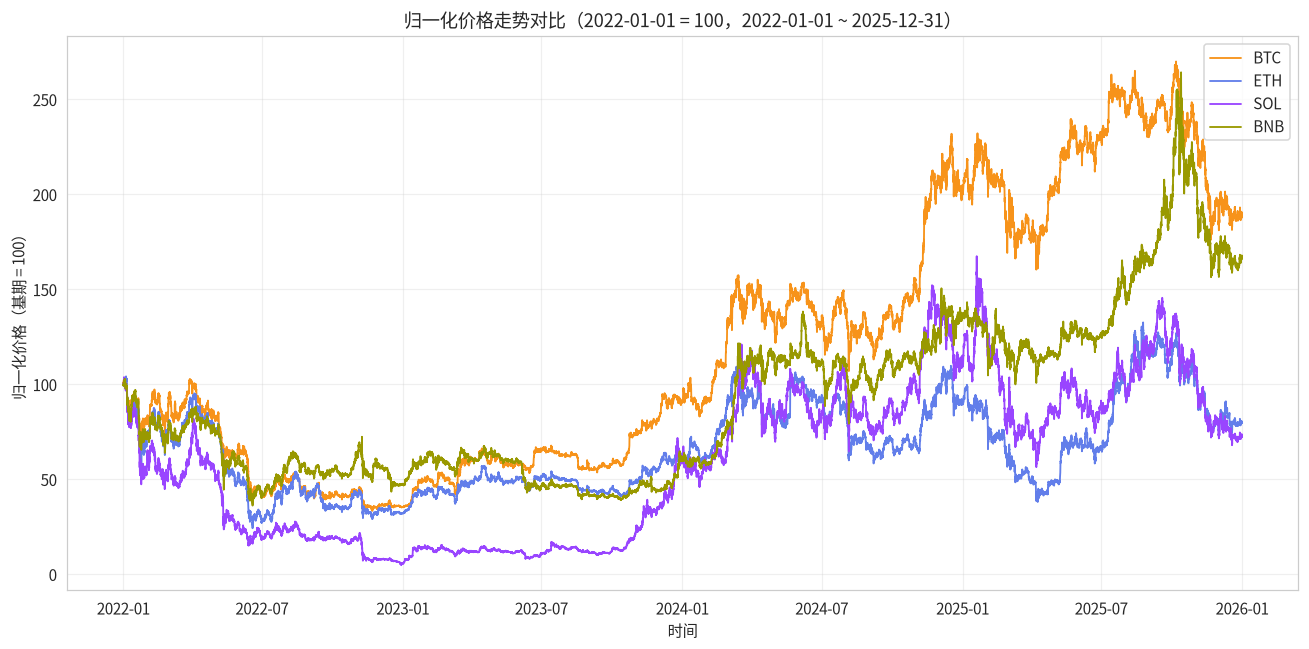

In [20]:
# 归一化图窗口：2022-01-01 ~ 2025-12-31
WINDOW = ('2022-01-01', '2025-12-31')

fig, ax = plt.subplots(figsize=(12, 6))
for name in ['BTC', 'ETH', 'SOL', 'BNB']:
    df = data[name].loc[WINDOW[0]:WINDOW[1]]
    norm = df['close'] / df['close'].iloc[0] * 100
    ax.plot(norm.index, norm, label=name, color=COLORS[name], linewidth=1.2)
    print(f'{name}: 归一化终值 = {norm.iloc[-1]:.1f}（基期 100，涨幅 {(norm.iloc[-1]-100):+.1f}%）')

ax.set_title('归一化价格走势对比（2022-01-01 = 100，2022-01-01 ~ 2025-12-31）')
ax.set_xlabel('时间'); ax.set_ylabel('归一化价格（基期 = 100）')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 相关系数热力图

本图时间窗口为 **2022-01-01 ~ 2025-12-31**（与归一化图一致，避开 SOL 早期独立发展阶段）。

> 按日重采样取每日收盘价，再计算**日收益率**（`pct_change`），对日收益率序列求 Pearson 相关系数，反映四者在**涨跌同步性**上的相关程度。

日收益率样本数: 1460

相关系数矩阵：
        BTC     ETH     SOL     BNB
BTC  1.0000  0.8315  0.7386  0.7067
ETH  0.8315  1.0000  0.7371  0.7202
SOL  0.7386  0.7371  1.0000  0.6563
BNB  0.7067  0.7202  0.6563  1.0000



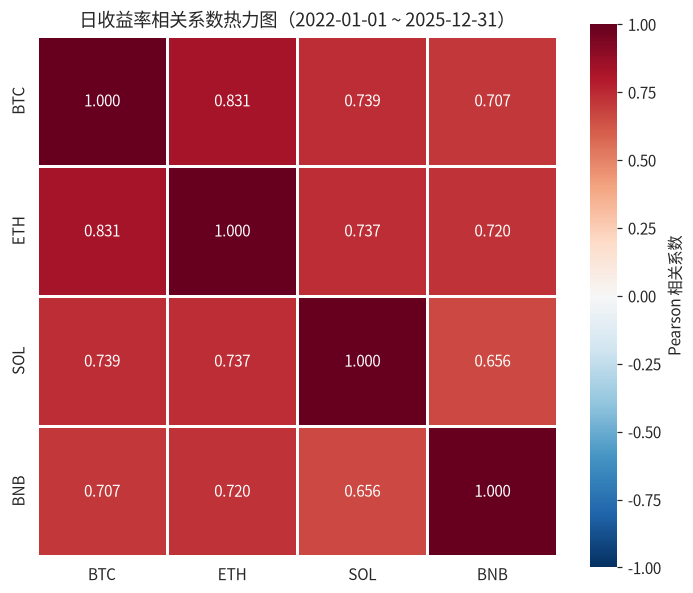

In [21]:
# 日频收盘价 → 日收益率（窗口 2022-01-01 ~ 2025-12-31）
WINDOW = ('2022-01-01', '2025-12-31')
daily_close = pd.DataFrame({name: df['close'].resample('D').last() for name, df in data.items()})
daily_close = daily_close.loc[WINDOW[0]:WINDOW[1]]
daily_ret = daily_close.pct_change().dropna()
print('日收益率样本数:', len(daily_ret))
print()

corr = daily_ret.corr()
print('相关系数矩阵：')
print(corr.round(4).to_string())
print()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.8, ax=ax,
            cbar_kws={'label': 'Pearson 相关系数'})
ax.set_title('日收益率相关系数热力图（2022-01-01 ~ 2025-12-31）')
plt.tight_layout()
plt.show()

### 小结

- **累计涨跌（基期 100 = 2022-01-01）**：BTC `187.9`（+87.9%）、BNB `167.0`（+67.0%）、ETH `79.9`（−20.1%）、SOL `72.4`（−27.6%）—— 与全区间口径不同：2021 年初低基数下 SOL 看似涨幅惊人，但 2022 年起 ETH / SOL 整体回落，仅 BTC 与 BNB 上涨，2022 年后的市场表现更贴近近期真实状态。
- **相关系数（日收益率，2022~2025）**：BTC–ETH `0.8315` 最高，BTC–SOL `0.7386`、ETH–SOL `0.7371`、ETH–BNB `0.7202`、BTC–BNB `0.7067`、SOL–BNB `0.6563` —— 四者高度正相关；BNB 与其余三者的相关性（0.66 ~ 0.72）略低于 BTC / ETH / SOL 之间的水平（0.74 ~ 0.83），相对独立一些。
- **年化波动率（日频，2022~2025）**：BTC `51.3%`、BNB `57.8%`、ETH `69.8%`、SOL `97.2%` —— SOL 波动最大，BNB 波动与 BTC 接近。

> 四个币种高度正相关，说明它们受共同的加密市场系统性因素驱动；在做多资产组合或对冲分析时，需注意分散化效果有限。

***

## BTC / TRX / XLM

In [22]:
FILES2 = {
    'BTC': 'btc_usdt_1h.csv',
    'TRX': 'trx_usdt_1h.csv',
    'XLM': 'xlm_usdt_1h.csv',
}
COLORS2 = {'BTC': '#F7931A', 'TRX': '#EF0027', 'XLM': '#7B00FF'}

data2 = {name: load_hourly(DATA_DIR / f) for name, f in FILES2.items()}
data2 = {name: df.loc[START:END] for name, df in data2.items()}

for name, df in data2.items():
    print(f'{name}: {df.index.min()} ~ {df.index.max()}，共 {len(df):,} 根小时K线')

data2['XLM'].head()

BTC: 2021-01-01 00:00:00 ~ 2025-12-31 23:00:00，共 43,824 根小时K线
TRX: 2021-01-01 00:00:00 ~ 2025-12-31 23:00:00，共 43,824 根小时K线
XLM: 2021-01-01 00:00:00 ~ 2025-12-31 23:00:00，共 43,824 根小时K线


,open,high,low,close,volume
timestamp,,,,,
2021-01-01 00:00:00,0.12780,0.12916,0.12663,0.12873,382483.7
2021-01-01 01:00:00,0.12873,0.13483,0.12873,0.13315,622025.0
2021-01-01 02:00:00,0.13315,0.13337,0.13143,0.13281,228721.6
2021-01-01 03:00:00,0.13229,0.13229,0.12993,0.12993,518719.9
2021-01-01 04:00:00,0.13055,0.13576,0.13055,0.13358,206568.6


### 收盘价折线图

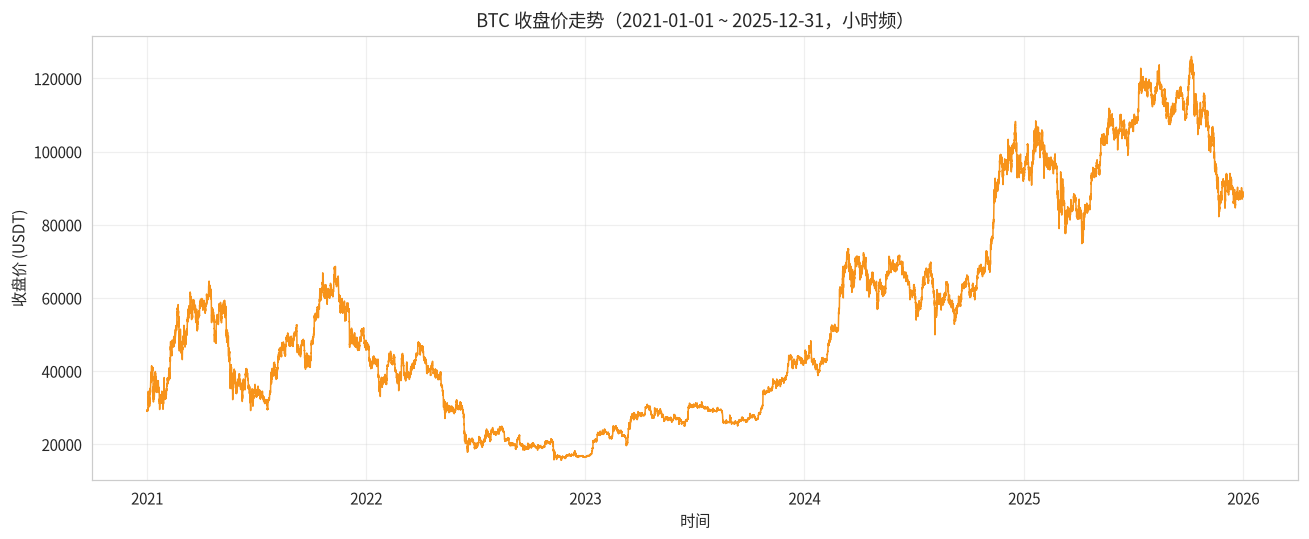

In [23]:
# BTC 收盘价
df = data2['BTC']
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index, df['close'], color=COLORS2['BTC'], linewidth=1.0)
ax.set_title('BTC 收盘价走势（2021-01-01 ~ 2025-12-31，小时频）')
ax.set_xlabel('时间'); ax.set_ylabel('收盘价 (USDT)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

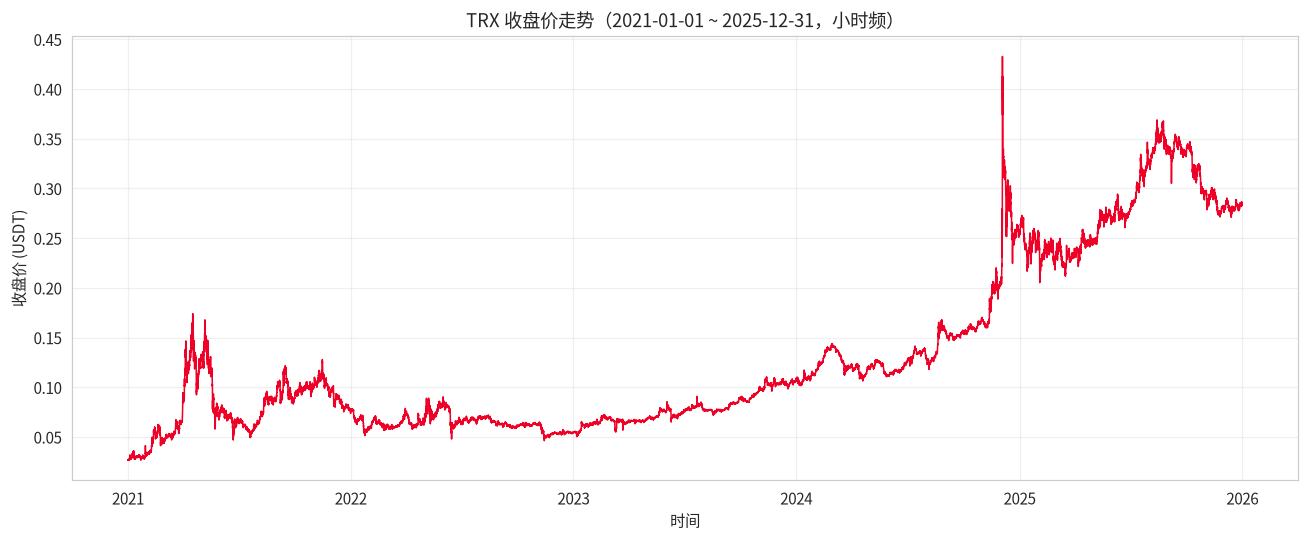

In [24]:
# TRX 收盘价
df = data2['TRX']
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index, df['close'], color=COLORS2['TRX'], linewidth=1.0)
ax.set_title('TRX 收盘价走势（2021-01-01 ~ 2025-12-31，小时频）')
ax.set_xlabel('时间'); ax.set_ylabel('收盘价 (USDT)')
ax.ticklabel_format(style='plain', axis='y')   # 避免小数值显示为科学计数法
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

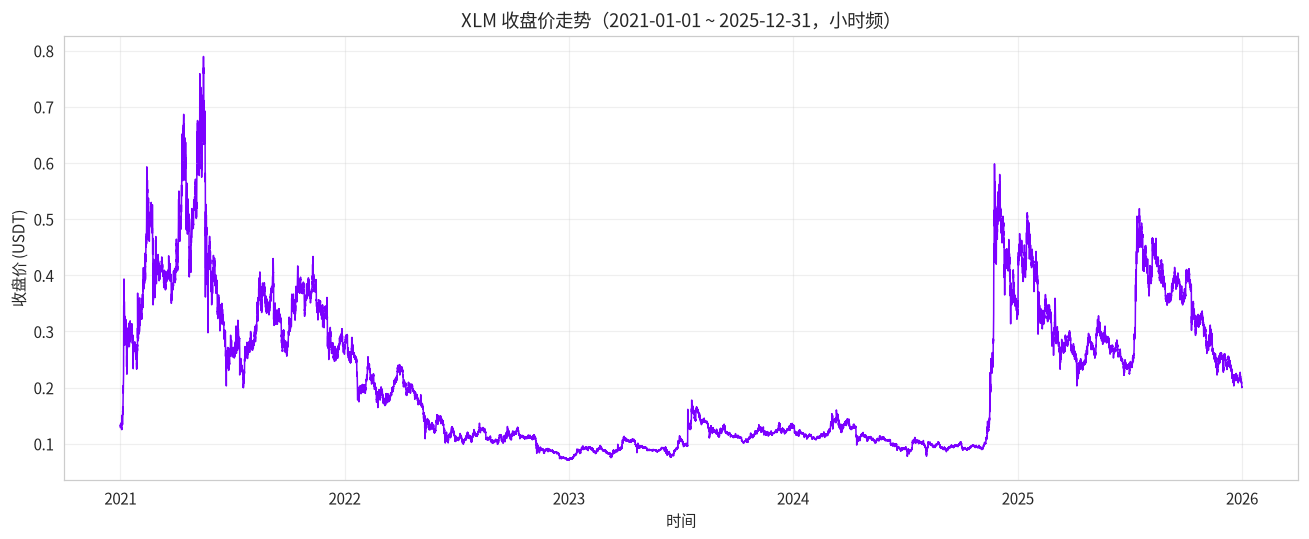

In [25]:
# XLM 收盘价
df = data2['XLM']
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index, df['close'], color=COLORS2['XLM'], linewidth=1.0)
ax.set_title('XLM 收盘价走势（2021-01-01 ~ 2025-12-31，小时频）')
ax.set_xlabel('时间'); ax.set_ylabel('收盘价 (USDT)')
ax.ticklabel_format(style='plain', axis='y')   # 避免小数值显示为科学计数法
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 归一化价格走势

与第一组保持一致，本图时间窗口为 **2022-01-01 ~ 2025-12-31**。

采用**基期归一化**：以窗口内第一个收盘价（2022-01-01）为基准 100，`normalized = close / close_0 * 100`，同图对比三个币种的相对涨幅。

BTC: 归一化终值 = 187.9（基期 100，涨幅 +87.9%）
TRX: 归一化终值 = 374.9（基期 100，涨幅 +274.9%）
XLM: 归一化终值 = 74.6（基期 100，涨幅 -25.4%）


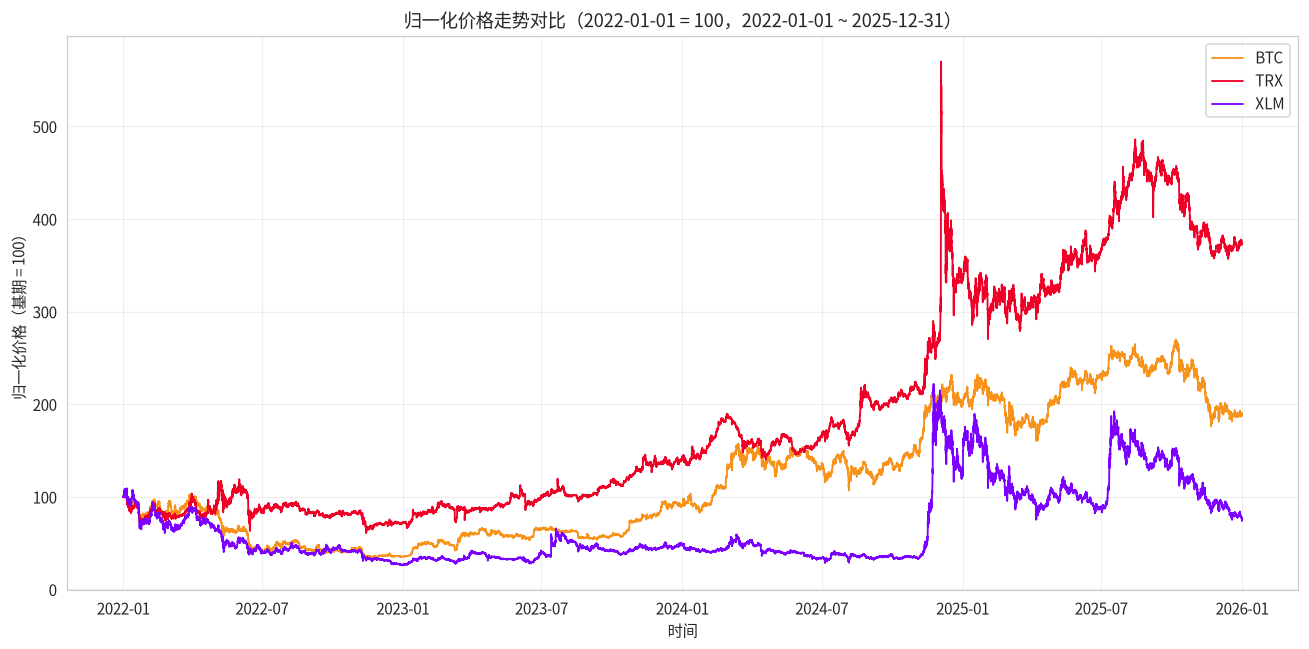

In [14]:
# 归一化图窗口：2022-01-01 ~ 2025-12-31（与第一组一致）
WINDOW2 = ('2022-01-01', '2025-12-31')

fig, ax = plt.subplots(figsize=(12, 6))
for name in ['BTC', 'TRX', 'XLM']:
    df = data2[name].loc[WINDOW2[0]:WINDOW2[1]]
    norm = df['close'] / df['close'].iloc[0] * 100
    ax.plot(norm.index, norm, label=name, color=COLORS2[name], linewidth=1.2)
    print(f'{name}: 归一化终值 = {norm.iloc[-1]:.1f}（基期 100，涨幅 {(norm.iloc[-1]-100):+.1f}%）')

ax.set_title('归一化价格走势对比（2022-01-01 = 100，2022-01-01 ~ 2025-12-31）')
ax.set_xlabel('时间'); ax.set_ylabel('归一化价格（基期 = 100）')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 相关系数热力图

与第一组保持一致，本图时间窗口为 **2022-01-01 ~ 2025-12-31**。

先按日重采样取每日收盘价，再计算**日收益率**（`pct_change`）的 Pearson 相关系数，反映涨跌同步性。

日收益率样本数: 1460

相关系数矩阵：
        BTC     TRX     XLM
BTC  1.0000  0.3682  0.5568
TRX  0.3682  1.0000  0.3179
XLM  0.5568  0.3179  1.0000



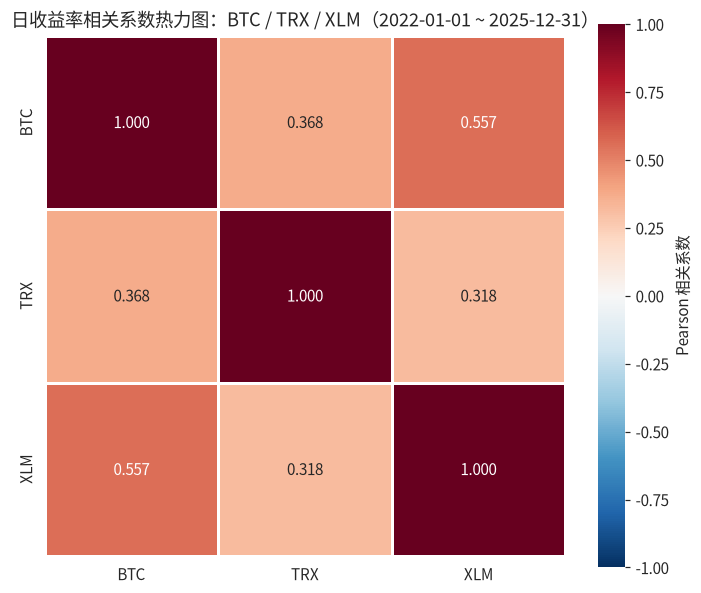

In [15]:
# 日频收盘价 → 日收益率（窗口 2022-01-01 ~ 2025-12-31）
WINDOW2 = ('2022-01-01', '2025-12-31')
daily_close2 = pd.DataFrame({name: df['close'].resample('D').last() for name, df in data2.items()})
daily_close2 = daily_close2.loc[WINDOW2[0]:WINDOW2[1]]
daily_ret2 = daily_close2.pct_change().dropna()
print('日收益率样本数:', len(daily_ret2))
print()

corr2 = daily_ret2.corr()
print('相关系数矩阵：')
print(corr2.round(4).to_string())
print()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr2, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.8, ax=ax,
            cbar_kws={'label': 'Pearson 相关系数'})
ax.set_title('日收益率相关系数热力图：BTC / TRX / XLM（2022-01-01 ~ 2025-12-31）')
plt.tight_layout()
plt.show()

## 小结

> 归一化图与相关系数图口径为 **2022-01-01 ~ 2025-12-31**（与第一组保持一致）；三张收盘价折线图为 2021-01-01 ~ 2025-12-31 全区间。

- **累计涨跌（基期 100 = 2022-01-01）**：TRX `374.9`（+274.9%）、BTC `187.9`（+87.9%）、XLM `74.6`（−25.4%）—— 2022 年起 TRX 领涨，XLM 与 ETH / SOL 类似整体回落。
- **相关系数（日收益率，2022~2025）**：BTC–XLM `0.5568` 最高，BTC–TRX `0.3682` 居中，TRX–XLM `0.3179` 最低 —— TRX 与 BTC / XLM 的联动都很弱，分散化价值突出；XLM 与 BTC 的相关性（0.56）明显高于 TRX。
- **年化波动率（日频，2022~2025）**：BTC `51.3%`、TRX `70.4%`、XLM `88.5%` —— XLM 波动最大。

> 与第一组对比：2022~2025 下 BTC/ETH/SOL/BNB 的日收益率相关性在 0.66 ~ 0.83，而 BTC/TRX/XLM 在 0.32 ~ 0.56，后一组相关性显著更低，作为组合成分的分散化价值更高。